In [1]:
import seaborn as sb
import numpy as np
import random
import math
import pandas as pd
import matplotlib.pyplot as plt
import scipy as sc

In [ ]:
Сгенерировать выборку указанного вида при некотором θ, построить по ней график функции
g(θ) = n−1 ln L(θ) (в пункте б) – обычного) для 
(a) X1, . . . , Xn ∼ N (0, θ),
(b) X1, . . . , Xn ∼ R[0, θ].
при n = 1, 5, 20, 100. 
Отметить
на графике настоящее значение параметра и ОМП. Что такое информация Фишера с точки зрения
предельного поведения g(θ)?

In [2]:
tetta = 8
numbers = [5,20,50, 100]

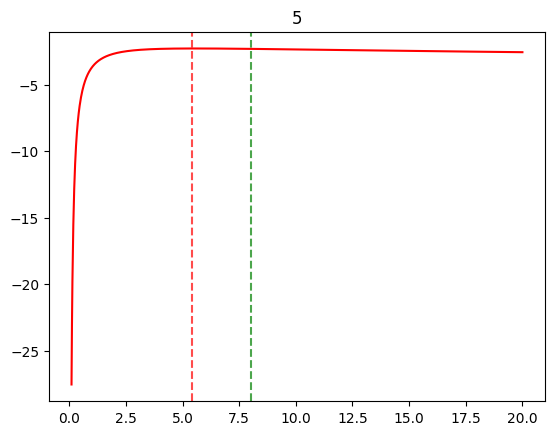

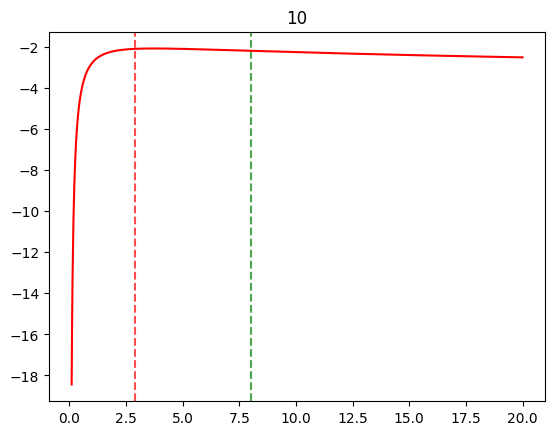

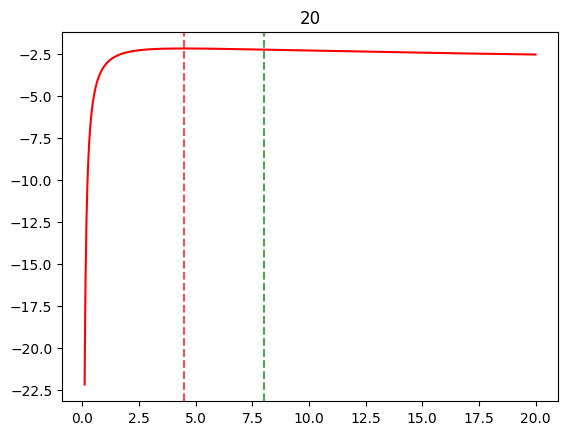

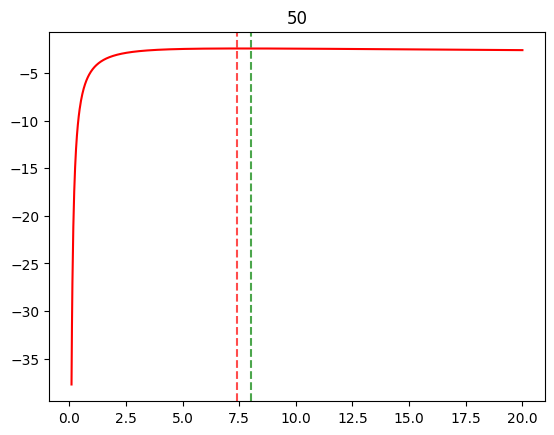

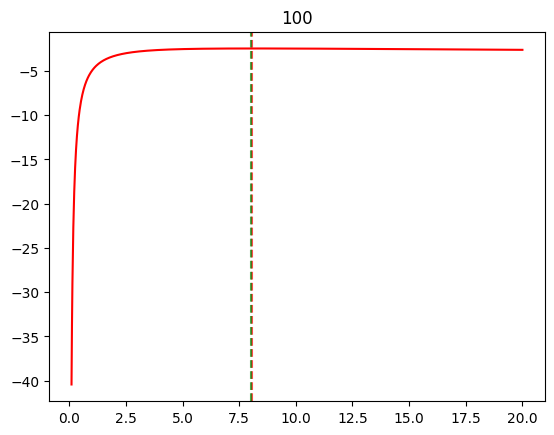

In [11]:
def g_norm(tetta, n, x):
    return( (-0.5)*np.log(2*np.pi*tetta) - np.sum(x**2)/(2*n*tetta) )

for n in numbers:
    x = np.random.normal(loc = 0, scale = np.sqrt(tetta), size = n)
    a = np.linspace(0.1,20,1000) 
    g = [g_norm(tet, n, x) for tet in a]
    plt.axvline(x=np.mean(x**2)-(np.mean(x))**2, color='red', linestyle='--', alpha=0.7)
    plt.axvline(x=tetta, color='green', linestyle='--', alpha=0.7)
    plt.plot(a, g, color = "red")
    plt.title(n)
    plt.show()

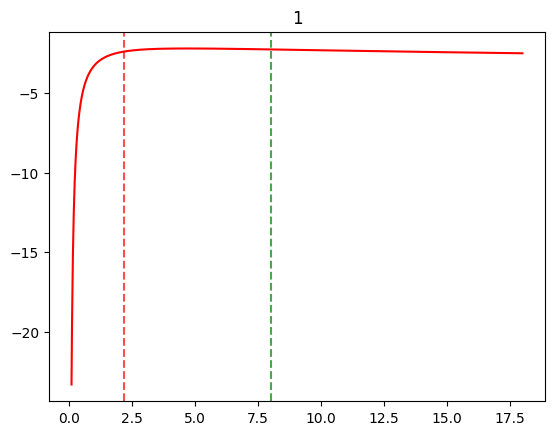

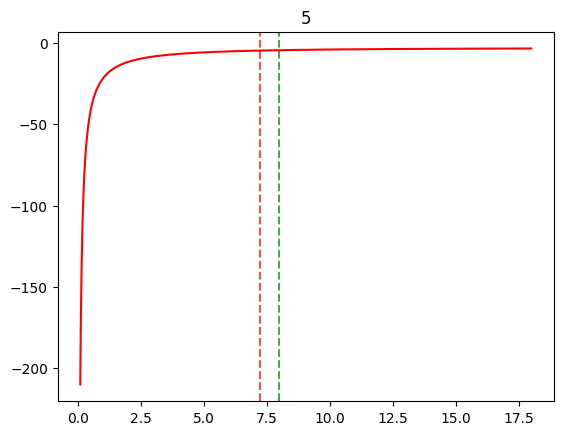

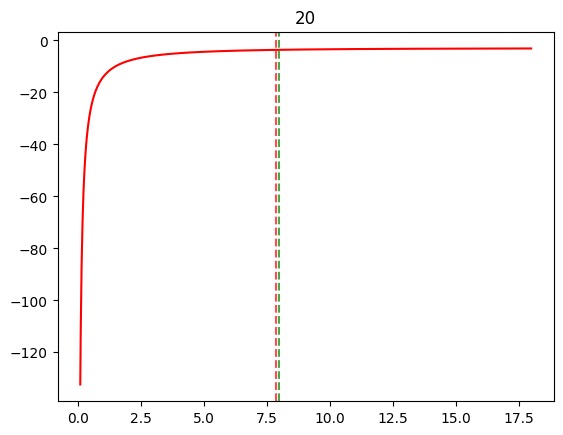

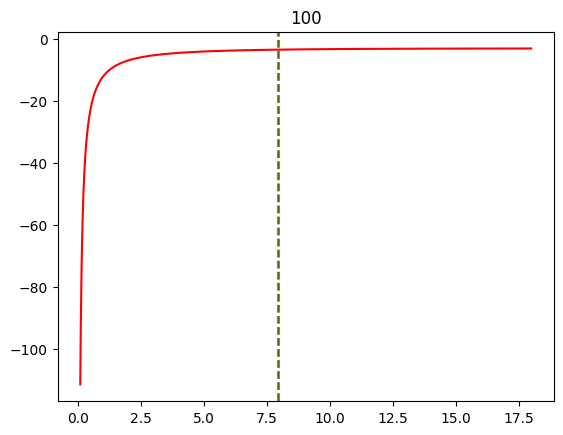

In [12]:
def g_uni(tetta, n, x):
    for i in range(n):
        if x[i]< 0 or x[i]>tetta:
            return(0)
    return(1/(n*tetta**n))
for n in numbers:
    x = np.random.uniform(0,tetta, size = n)
    a = np.linspace(0.1,tetta +10 ,1000)
    g = [g_norm(tet, n, x) for tet in a]
    plt.axvline(x=np.max(x), color='red', linestyle='--', alpha=0.7)
    plt.axvline(x=tetta, color='green', linestyle='--', alpha=0.7)
    plt.plot(a, g, color = "red")
    plt.title(n)
    plt.show()

In [ ]:
 2 n2 Пусть X1, . . . , Xn выборки из распределения, являющегося смесью N (θ1, θ2) и N (0, 1) c весами 1/2,
1/2; здесь требуется построить графики L(θ2) при фиксированном значении первого параметра:
а) θ1 – настоящее значение (с которым генерировалась выборка),
б) θ1 = X1. 
Во втором случае
рассмотреть близкие к нулю значения θ2 при больших n.

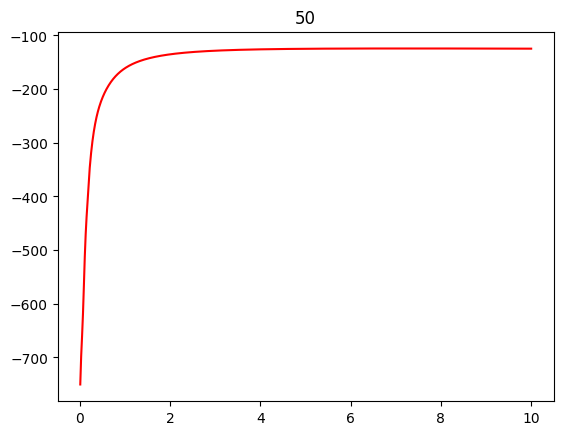

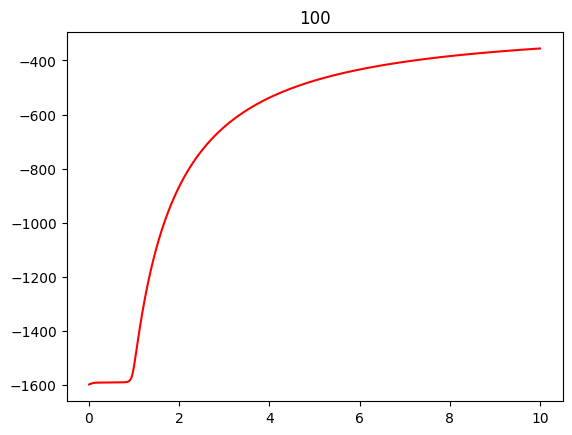

In [16]:
def vyborka(tetta1, tetta2, n):
    x = [0]*n
    for i in range(n):
        if(np.random.binomial(1,0.5) == 1):
            x[i] = np.random.normal(loc = 0, scale = 1)
        else:
            x[i] = np.random.normal(loc = tetta1, scale = np.sqrt(tetta2))
    return(x)
            
def lh(tetta1, tetta2, n, x):
    ans = 0
    for i in range(n):
        ans+= np.log ( 0.5*(sc.stats.norm.pdf(x[i], loc = 0, scale = 1) + sc.stats.norm.pdf(x[i], loc = tetta1, scale = np.sqrt(tetta2)) ) )
    return(ans)


tetta1 = 8
tetta2 = 4
n = 50
x = vyborka(tetta1, tetta2, n)
t2 = np.linspace(0.01, 10,1000)
l = [lh(tetta1,a,n,x) for a in t2]
plt.plot(t2, l, color = "red")
plt.title(n)
plt.show()

n = 100
x = vyborka(tetta1, tetta2, n)
t2 = np.linspace(0.01, 10,1000)
l = [lh(x[0],a,n,x) for a in t2]
plt.plot(t2, l, color = "red")
plt.title(n)
plt.show()

In [ ]:
3 Xi имеют распределение Коши, где в варианте 1 неизвестный параметр — сдвиг θ, а в варианте 2
– масштаб. Построить ОМП по выборке размера n = 5, 10, 20, 50, 100. Для каждого n генерировать
k = 500 выборок X1, . . . , Xn, для каждой найти значение ОМП и θb, найти выборочное среднее и
выборочную дисперсию ОМП и θb и сравнить их. Здесь θb для первого варианта – это выборочная
медиана, а для второго – половина интерквартильного размаха, то есть полуразность верхнего и
нижнего выборочного квартиля.

In [44]:
def lnlh(t, data, n):
    ans = 0
    for k in range(n):
        ans += np.log(sc.stats.cauchy.pdf(data[k], loc = t) )
    return(ans)
    
tetta = 8
k = 500
numbers = [5,10,20,50,100]
for n in numbers:
    mle = [0]*k
    medd = [0]*k
    for j in range(k):
        data = np.random.standard_cauchy(size = n)
        data+=tetta
        mle[j] = sc.optimize.minimize(lambda x: -lnlh(x, data, n), x0=np.median(data), method='BFGS').x[0]
        medd[j] = np.median(data)
    print(np.mean(mle), np.mean(medd), np.std(mle), np.std(medd))

8.01492494097279 8.016278900332086 0.9758898481922458 0.9958559147380359
7.975090628639403 7.978806928824446 0.5013706320972802 0.5239219979035071
7.992700345750473 7.998475919417447 0.33993077179127384 0.36057092922381967
8.010488329161404 8.012078256503425 0.20665112046079576 0.2290084501545467
7.994367605428344 7.997809547632897 0.14413570108453996 0.1556794649538004


In [ ]:
4. 1 вариант – X1, ..., Xn ∼ N (θ, 1), 2 вариант – X1, . . . , Xn ∼ N (0, θ), θb1 – ОММ, θb2 – ОМС, θb3 – ОМП.
(a) Построить по выборке θbi , i = 1, 2, 3 (найти численно или аналитически, как удобнее).
(b) Сравнить, какая из оценок чаще оказывается ближе к θ при разных n, смоделировав для этого по 1000 реализаций (для каждого n).

In [3]:
def spacing(x, data, n, tetta):
    np.sort(data)
    ans = sc.stats.norm.cdf(data[0], loc = tetta, scale = 1)
    for i in range(n-2):
        ans*= sc.stats.norm.cdf(data[i+1], loc = tetta, scale = 1) - sc.stats.norm.cdf(data[i], loc = tetta, scale = 1)
    ans*=1 - sc.stats.norm.cdf(data[n-1], loc = tetta, scale = 1)
    return(ans)
mle = [0]*1000
me = [0]*1000
se = [0]*1000
tetta=8
for n in numbers:
    mlefreq=0
    mefreq=0
    sefreq=0
    for j in range(1000):
        data = np.random.normal(loc = tetta, scale = 1, size = n)
        mle[j] = np.mean(data)
        me[j] = np.mean(data)
        se[j] = sc.optimize.minimize(lambda x: -spacing(x, data, n, tetta), x0=np.median(data), method='BFGS').x[0]
        
    for j in range(1000):
        if np.abs(tetta-mle[j]) <= np.abs(tetta-me[j]) and np.abs(tetta-mle[j]) <= np.abs(tetta-se[j]):
            mlefreq+=1
        if np.abs(tetta-me[j]) <= np.abs(tetta-mle[j]) and np.abs(tetta-me[j]) <= np.abs(tetta-se[j]):
            mefreq+=1
        else:
            sefreq+=1
    print(n, "mle:", mlefreq/1000, ", me:",mefreq/1000, ", se:", sefreq/1000)

5 mle: 0.584 , me: 0.584 , se: 0.416
20 mle: 0.632 , me: 0.632 , se: 0.368
50 mle: 0.588 , me: 0.588 , se: 0.412
100 mle: 0.623 , me: 0.623 , se: 0.377


In [ ]:
(c) Построить гистограммы для √n(θbi − θ) на одном графике, сравнить разбросы.

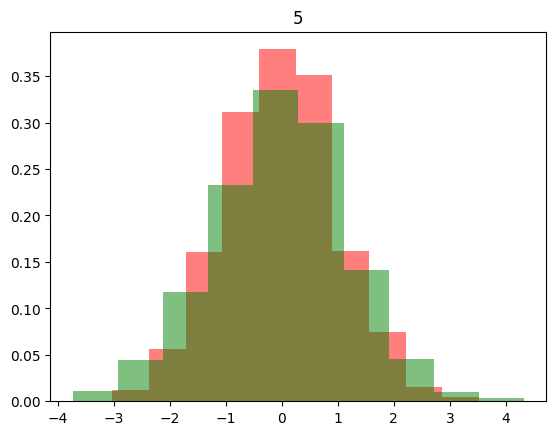

0.995225574642874 1.1905316545642624


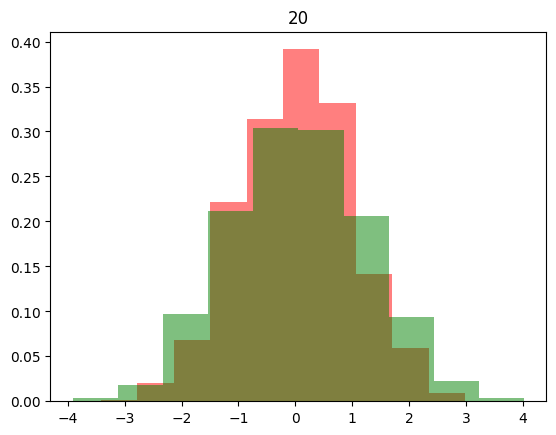

0.9801215506591143 1.1840140261339573


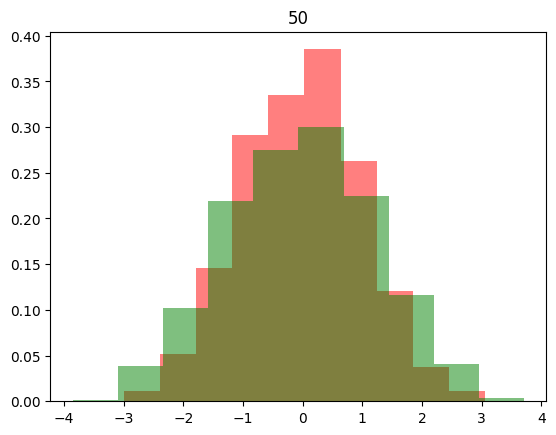

0.9934187265485647 1.2343909574130447


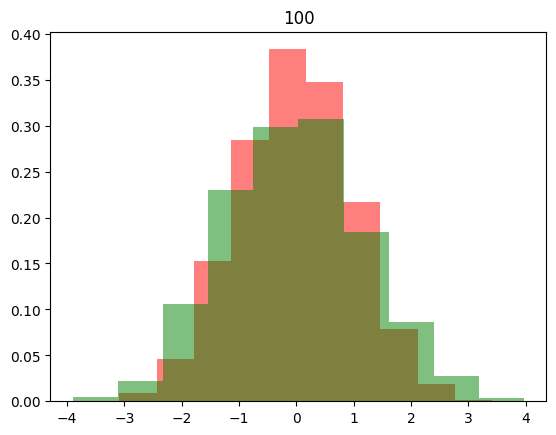

0.9880267835294818 1.1929246531616589


In [43]:
mle = [0]*1000
me = [0]*1000
se = [0]*1000

for n in numbers:
    mlefreq=0
    mefreq=0
    sefreq=0
    for j in range(1000):
        data = np.random.normal(loc = tetta, scale = 1, size = n)
        mle[j] = np.mean(data)
        me[j] = np.mean(data)
        se[j] = sc.optimize.minimize(lambda x: -spacing(x, data, n, tetta), x0=np.median(data), method='BFGS').x[0]
    mle_clt = [np.sqrt(n)*(a-tetta) for a in mle]
    me_clt = [np.sqrt(n)*(a-tetta) for a in me]
    se_clt = [np.sqrt(n)*(a-tetta) for a in se]
    plt.hist(mle_clt, color = "red", alpha=0.5, density = True) 
    #plt.hist(me_clt, color = "blue", alpha=0.5, density = True)  
    plt.hist(se_clt, color = "green", alpha=0.5, density = True)  
    plt.title(n)
    plt.show()

    print(np.sqrt(n)*np.std(mle), np.sqrt(n)*np.std(se))

In [ ]:
(d) * Посчитать асимтотическую дисперсию этих оценок, построить график (по θ, сравнить с
выборочной дисперсией (нормированной)).
у всех тожд 1???

In [ ]:
5*. 1-й вариант: X1, ..., Xn ∼ Beta(a, b)
θ = (a, b), θb1 = (ba1,bb1) – ОМП, θb2 = (ba2,bb2) – ОМС.
(a) Построить по выборке оценки θb1 и θb2 (найти численно).
(b) Сравнить, какая из оценок чаще оказывается ближе к θ при разных n (отдельно по каждой
координате и в смысле расстояния на плоскости), смоделировав для этого по 1000 реализаций
(для каждого n).
(c) Построить гистограммы (одномерные) для √n(θbi − θ) на одном графике, сравнить разбросы.

Параметры по умолчанию: n=50, a=5.0, b=5.0
Найденное ОМП (первые 5 оценок):
[[4.11524139 4.19575635]
 [4.70639115 4.64211381]
 [5.16081446 5.35659025]
 [4.97508197 5.40967896]
 [6.97343023 7.0411415 ]]

Сравнение оценок:
Ближе по a: ОМП = 546, ОМС = 454
Ближе по b: ОМП = 537, ОМС = 463
Ближе в евклидовом расстоянии: ОМП = 535, ОМС = 465


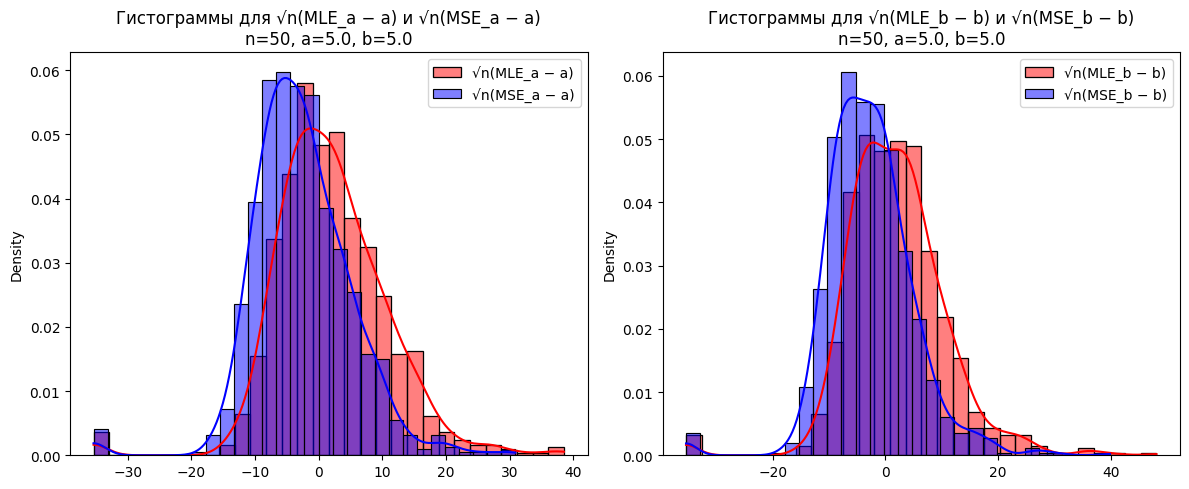

In [1]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import beta
from scipy.optimize import minimize
from scipy.spatial.distance import euclidean

num_experiments = 1000

def neg_log_likelihood(params, data):
    current_a, current_b = params[0], params[1]
    log_likelihood_values = beta.logpdf(data, a=current_a, b=current_b)
    return -np.sum(log_likelihood_values)

def neg_log_D(params, data):
    current_a, current_b = params[0], params[1]
    sorted_data = np.sort(data)
    cdf_values = beta.cdf(sorted_data, a=current_a, b=current_b)
    extended_cdf = np.concatenate(([0], cdf_values, [1]))
    spacings = np.diff(extended_cdf)
    log_spacings = np.log(spacings)
    return -np.sum(log_spacings)

num = 50
par_a = 5.0
par_b = 5.0

Res_MLE_a = np.zeros(num_experiments)
Res_MLE_b = np.zeros(num_experiments)
Res_MSE_a = np.zeros(num_experiments)
Res_MSE_b = np.zeros(num_experiments)
count_MLE_a = 0
count_MLE_b = 0
count_MSE_a = 0
count_MSE_b = 0  
count_MSE = 0
count_MLE = 0 

i = 0
while(i < num_experiments):
    X = beta.rvs(a=par_a, b=par_b, size=num)
    sample_mean = np.mean(X)
    sample_var = np.var(X)
    common_term = ((sample_mean*(1 - sample_mean))/sample_var) - 1
    initial_a = sample_mean * common_term
    initial_b = (1 - sample_mean) * common_term
    
    initial_guess = [initial_a, initial_b]
    bounds = [(1e-6, None), (1e-6, None)]
    result_MLE = minimize(fun=neg_log_likelihood, x0=initial_guess, args=(X,), method='L-BFGS-B', bounds=bounds)
    result_MSE = minimize(fun=neg_log_D, x0=initial_guess, args=(X,), method='L-BFGS-B', bounds=bounds)
    
    if result_MLE.success and result_MSE.success:
        Res_MLE_a[i], Res_MLE_b[i] = result_MLE.x
        Res_MSE_a[i], Res_MSE_b[i] = result_MSE.x
    else:
        pass

    theta = (par_a, par_b)
    p_MLE = (Res_MLE_a[i], Res_MLE_b[i])
    p_MSE = (Res_MSE_a[i], Res_MSE_b[i])

    if(np.abs(Res_MSE_a[i] - par_a) > np.abs(Res_MLE_a[i] - par_a)):
        count_MLE_a += 1
    else:
        count_MSE_a += 1

    if(np.abs(Res_MSE_b[i] - par_b) > np.abs(Res_MLE_b[i] - par_b)):
        count_MLE_b += 1
    else:
        count_MSE_b += 1

    if(euclidean(p_MSE, theta) > euclidean(p_MLE, theta)):
        count_MLE += 1
    else:
        count_MSE += 1
    i += 1

Res_MLE = np.column_stack((Res_MLE_a, Res_MLE_b))
Res_MSE = np.column_stack((Res_MSE_a, Res_MSE_b))

print(f"Параметры по умолчанию: n={num}, a={par_a}, b={par_b}")
print("Найденное ОМП (первые 5 оценок):")
print(Res_MLE[:5])

print("\nСравнение оценок:")
print(f"Ближе по a: ОМП = {count_MLE_a}, ОМС = {count_MSE_a}")
print(f"Ближе по b: ОМП = {count_MLE_b}, ОМС = {count_MSE_b}")
print(f"Ближе в евклидовом расстоянии: ОМП = {count_MLE}, ОМС = {count_MSE}")

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.title(f"Гистограммы для √n(MLE_a − a) и √n(MSE_a − a)\nn={num}, a={par_a}, b={par_b}")
sns.histplot(np.sqrt(num)*(Res_MLE_a - par_a), bins=30, color="red", kde=True, stat='density', label='√n(MLE_a − a)')
sns.histplot(np.sqrt(num)*(Res_MSE_a - par_a), bins=30, color="blue", kde=True, stat='density', label='√n(MSE_a − a)')
plt.legend()

plt.subplot(1, 2, 2)
plt.title(f"Гистограммы для √n(MLE_b − b) и √n(MSE_b − b)\nn={num}, a={par_a}, b={par_b}")
sns.histplot(np.sqrt(num)*(Res_MLE_b - par_b), bins=30, color="red", kde=True, stat='density', label='√n(MLE_b − b)')
sns.histplot(np.sqrt(num)*(Res_MSE_b - par_b), bins=30, color="blue", kde=True, stat='density', label='√n(MSE_b − b)')
plt.legend()

plt.tight_layout()
plt.show()